# **SI Project:- Used Laptop Resale Value Prediction 💻**


---

Name:- Sanika Bhanuse

Roll no:- 21

Section/Batch:-B2_B2

In [1]:
import requests
from bs4 import BeautifulSoup

url = "https://webscraper.io/test-sites/e-commerce/static/computers/laptops"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print("Status Code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")
print(soup.title.text)

Status Code: 200
Static | Web Scraper Test Sites


In [2]:
laptops = soup.find_all("div", class_="thumbnail")

print("Total laptops found:", len(laptops))

Total laptops found: 6


In [3]:
soup.prettify()

'<!DOCTYPE html>\n<html lang="en">\n <head>\n  <script src="https://app.termly.io/resource-blocker/04d89d8c-0d17-44fe-bead-65034ef2b40c">\n  </script>\n  <!-- Google Tag Manager -->\n  <script nonce="0ua9LzrKe5IsVK2mCupGxzZEvTZOV5Tz">\n   (function (w, d, s, l, i) {\n\t\tw[l] = w[l] || [];\n\t\tw[l].push({\n\t\t\t\'gtm.start\':\n\t\t\t\tnew Date().getTime(), event: \'gtm.js\'\n\t\t});\n\t\tvar f = d.getElementsByTagName(s)[0],\n\t\t\tj = d.createElement(s), dl = l != \'dataLayer\' ? \'&l=\' + l : \'\';\n\t\tj.async = true;\n\t\tj.src =\n\t\t\t\'https://www.googletagmanager.com/gtm.js?id=\' + i + dl;\n\t\tf.parentNode.insertBefore(j, f);\n\t})(window, document, \'script\', \'dataLayer\', \'GTM-NVFPDWB\');\n  </script>\n  <!-- End Google Tag Manager -->\n  <title>\n   Static | Web Scraper Test Sites\n  </title>\n  <meta charset="utf-8"/>\n  <meta content="IE=edge,chrome=1" http-equiv="X-UA-Compatible"/>\n  <meta content="web scraping,Web Scraper,Chrome extension,Crawling,Cross platform s

In [4]:
print(response.text)

<!DOCTYPE html>
<html lang="en">
<head>
	<script src="https://app.termly.io/resource-blocker/04d89d8c-0d17-44fe-bead-65034ef2b40c"></script>
	<!-- Google Tag Manager -->
<script nonce="0ua9LzrKe5IsVK2mCupGxzZEvTZOV5Tz">(function (w, d, s, l, i) {
		w[l] = w[l] || [];
		w[l].push({
			'gtm.start':
				new Date().getTime(), event: 'gtm.js'
		});
		var f = d.getElementsByTagName(s)[0],
			j = d.createElement(s), dl = l != 'dataLayer' ? '&l=' + l : '';
		j.async = true;
		j.src =
			'https://www.googletagmanager.com/gtm.js?id=' + i + dl;
		f.parentNode.insertBefore(j, f);
	})(window, document, 'script', 'dataLayer', 'GTM-NVFPDWB');</script>
<!-- End Google Tag Manager -->
	<title>Static | Web Scraper Test Sites</title>
	<meta charset="utf-8">
	<meta http-equiv="X-UA-Compatible" content="IE=edge,chrome=1">

	<meta name="keywords"
		content="web scraping,Web Scraper,Chrome extension,Crawling,Cross platform scraper"/>
	<meta name="description"
		content="Test Web Scraper&#039;s features and p

In [5]:
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, "html.parser")

In [6]:
print(soup.find("title"))

<title>Static | Web Scraper Test Sites</title>


In [7]:
laptops = soup.find_all("div", class_="card thumbnail")

print("Total laptops on page:", len(laptops))

Total laptops on page: 6


In [8]:
titles = []

for laptop in laptops:
    title = laptop.find("a", class_="title").text.strip()
    titles.append(title)

print(titles)

['Packard 255 G2', 'Aspire E1-510', 'ThinkPad T540p', 'ProBook', 'ThinkPad X240', 'Aspire E1-572G']


In [9]:
prices = []

for laptop in laptops:
    price = laptop.find("h4", class_="price").text.strip()
    prices.append(price)

print(prices)

['$416.99', '$306.99', '$1178.99', '$739.99', '$1311.99', '$581.99']


In [10]:
ratings = []

for laptop in laptops:
    rating = laptop.find("p", attrs={"data-rating": True})["data-rating"]
    ratings.append(rating)

print(ratings)

['2', '3', '1', '4', '3', '1']


In [11]:
reviews = []

for laptop in laptops:
    review = laptop.find("p", class_="review-count").text.strip()
    reviews.append(review)

print(reviews)

['2 reviews', '2 reviews', '2 reviews', '8 reviews', '12 reviews', '2 reviews']


In [12]:

import pandas as pd

df1 = pd.DataFrame({
    "Laptop_Name": titles,
    "Price": prices,
    "Rating": ratings,
    "Reviews": reviews
})

df1

,Laptop_Name,Price,Rating,Reviews
0,Packard 255 G2,$416.99,2,2 reviews
1,Aspire E1-510,$306.99,3,2 reviews
2,ThinkPad T540p,$1178.99,1,2 reviews
3,ProBook,$739.99,4,8 reviews
4,ThinkPad X240,$1311.99,3,12 reviews
5,Aspire E1-572G,$581.99,1,2 reviews


In [13]:
data = []

for page in range(1, 21):

    url = f"https://webscraper.io/test-sites/e-commerce/static/computers/laptops?page={page}"

    response = requests.get(url, headers=headers)
    soup = BeautifulSoup(response.text, "html.parser")

    # Each laptop card
    laptops = soup.find_all("div", class_="card thumbnail")

    print(f"Page {page}: {len(laptops)} laptops")

    for laptop in laptops:

        name = laptop.find("a", class_="title").text.strip()

        price = laptop.find("h4", class_="price").text.strip().replace("$", "")

        description = laptop.find("p", class_="description").text.strip()

        reviews = laptop.find("p", class_="review-count").text.split()[0]

        rating = laptop.find("p", attrs={"data-rating": True})["data-rating"]

        data.append([
            name,
            float(price),
            description,
            int(reviews),
            int(rating)
        ])

df = pd.DataFrame(data, columns=[
    "Laptop_Name",
    "Price",
    "Description",
    "Reviews",
    "Rating"
])

print("\nTotal Records:", len(df))
df

Page 1: 6 laptops
Page 2: 6 laptops
Page 3: 6 laptops
Page 4: 6 laptops
Page 5: 6 laptops
Page 6: 6 laptops
Page 7: 6 laptops
Page 8: 6 laptops
Page 9: 6 laptops
Page 10: 6 laptops
Page 11: 6 laptops
Page 12: 6 laptops
Page 13: 6 laptops
Page 14: 6 laptops
Page 15: 6 laptops
Page 16: 6 laptops
Page 17: 6 laptops
Page 18: 6 laptops
Page 19: 6 laptops
Page 20: 3 laptops

Total Records: 117


,Laptop_Name,Price,Description,Reviews,Rating
0,Packard 255 G2,416.99,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",2,2
1,Aspire E1-510,306.99,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",2,3
2,ThinkPad T540p,1178.99,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",2,1
3,ProBook,739.99,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",8,4
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3
...,...,...,...,...,...
112,Lenovo ThinkPa...,1349.23,"Lenovo ThinkPad T470, 14"" FHD IPS, Core i5-720...",5,1
113,Lenovo ThinkPa...,1362.24,"Lenovo ThinkPad Yoga 370 Black, 13.3"" FHD IPS ...",12,2
114,Toshiba Porteg...,1366.32,"Toshiba Portege X20W-D-10V Black/Blue, 12.5"" F...",11,1
115,Asus ASUSPRO B...,1381.13,"Asus ASUSPRO B9440UA-GV0279R Gray, 14"" FHD, Co...",4,1


In [14]:
df.to_csv("used_laptops_price.csv", index=False)

print(df)

           Laptop_Name    Price  \
0       Packard 255 G2   416.99   
1        Aspire E1-510   306.99   
2       ThinkPad T540p  1178.99   
3              ProBook   739.99   
4        ThinkPad X240  1311.99   
..                 ...      ...   
112  Lenovo ThinkPa...  1349.23   
113  Lenovo ThinkPa...  1362.24   
114  Toshiba Porteg...  1366.32   
115  Asus ASUSPRO B...  1381.13   
116  Asus ROG Strix...  1399.00   

                                           Description  Reviews  Rating  
0    15.6", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...        2       2  
1      15.6", Pentium N3520 2.16GHz, 4GB, 500GB, Linux        2       3  
2     15.6", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit        2       1  
3      14", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit        8       4  
4    12.5", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...       12       3  
..                                                 ...      ...     ...  
112  Lenovo ThinkPad T470, 14" FHD IPS, Core i5-720...       

In [16]:
from IPython.display import FileLink

FileLink("used_laptops_price.csv")


C:\Users\ACER\used_laptops_price.csv

In [17]:
import ipywidgets as widgets
from IPython.display import display

# Create and display the file upload widget
uploader = widgets.FileUpload(accept='.csv', multiple=False)
display(uploader)


FileUpload(value=(), accept='.csv', description='Upload')

In [18]:
df=pd.read_csv("used_laptops_price.csv")
df

,Laptop_Name,Price,Description,Reviews,Rating
0,Packard 255 G2,416.99,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",2,2
1,Aspire E1-510,306.99,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",2,3
2,ThinkPad T540p,1178.99,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",2,1
3,ProBook,739.99,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",8,4
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3
...,...,...,...,...,...
112,Lenovo ThinkPa...,1349.23,"Lenovo ThinkPad T470, 14"" FHD IPS, Core i5-720...",5,1
113,Lenovo ThinkPa...,1362.24,"Lenovo ThinkPad Yoga 370 Black, 13.3"" FHD IPS ...",12,2
114,Toshiba Porteg...,1366.32,"Toshiba Portege X20W-D-10V Black/Blue, 12.5"" F...",11,1
115,Asus ASUSPRO B...,1381.13,"Asus ASUSPRO B9440UA-GV0279R Gray, 14"" FHD, Co...",4,1


In [19]:
df.head()

,Laptop_Name,Price,Description,Reviews,Rating
0,Packard 255 G2,416.99,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",2,2
1,Aspire E1-510,306.99,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",2,3
2,ThinkPad T540p,1178.99,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",2,1
3,ProBook,739.99,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",8,4
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3


In [20]:
df.tail()

,Laptop_Name,Price,Description,Reviews,Rating
112,Lenovo ThinkPa...,1349.23,"Lenovo ThinkPad T470, 14"" FHD IPS, Core i5-720...",5,1
113,Lenovo ThinkPa...,1362.24,"Lenovo ThinkPad Yoga 370 Black, 13.3"" FHD IPS ...",12,2
114,Toshiba Porteg...,1366.32,"Toshiba Portege X20W-D-10V Black/Blue, 12.5"" F...",11,1
115,Asus ASUSPRO B...,1381.13,"Asus ASUSPRO B9440UA-GV0279R Gray, 14"" FHD, Co...",4,1
116,Asus ROG Strix...,1399.00,"Asus ROG Strix GL702VM-GC146T, 17.3"" FHD, Core...",10,3


In [21]:
df.shape

(117, 5)

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Laptop_Name  117 non-null    str    
 1   Price        117 non-null    float64
 2   Description  117 non-null    str    
 3   Reviews      117 non-null    int64  
 4   Rating       117 non-null    int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 16.9 KB


In [23]:
df.isnull().sum()

Laptop_Name    0
Price          0
Description    0
Reviews        0
Rating         0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df["Price"] = (
    df["Price"]
      .astype(str)
      .str.replace("$", "", regex=False)
      .astype(float)
)

df["Price"].head()

0     416.99
1     306.99
2    1178.99
3     739.99
4    1311.99
Name: Price, dtype: float64

In [26]:
import re

# Screen Size
df["Screen_Size"] = df["Description"].str.extract(r'(\d+\.?\d*)').astype(float)

# RAM (GB)
df["RAM_GB"] = df["Description"].str.extract(r'(\d+)GB').astype(float)

# Storage (GB)
def storage_to_gb(text):
    if pd.isna(text):
        return None

    tb = re.search(r'(\d+)TB', text)
    if tb:
        return int(tb.group(1)) * 1024

    gb = re.search(r'(\d+)GB', text)
    if gb:
        return int(gb.group(1))

    return None

df["Storage_GB"] = df["Description"].apply(storage_to_gb)

df[["Description", "Screen_Size", "RAM_GB", "Storage_GB"]]

,Description,Screen_Size,RAM_GB,Storage_GB
0,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",15.6,4.0,4
1,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",15.6,4.0,4
2,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",15.6,4.0,4
3,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",14.0,4.0,4
4,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12.5,8.0,8
...,...,...,...,...
112,"Lenovo ThinkPad T470, 14"" FHD IPS, Core i5-720...",470.0,8.0,8
113,"Lenovo ThinkPad Yoga 370 Black, 13.3"" FHD IPS ...",370.0,8.0,8
114,"Toshiba Portege X20W-D-10V Black/Blue, 12.5"" F...",20.0,8.0,8
115,"Asus ASUSPRO B9440UA-GV0279R Gray, 14"" FHD, Co...",9440.0,16.0,16


In [27]:
df.to_csv("cleaned_used_laptops.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [29]:
from IPython.display import FileLink

# This displays a clickable link to download the file
FileLink("cleaned_used_laptops.csv")


C:\Users\ACER\cleaned_used_laptops.csv

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
import ipywidgets as widgets
from IPython.display import display

# Create and display the file upload widget
uploader = widgets.FileUpload(accept='.csv', multiple=False)
display(uploader)


FileUpload(value=(), accept='.csv', description='Upload')

In [32]:
df = pd.read_csv("cleaned_used_laptops.csv")

df.head()

,Laptop_Name,Price,Description,Reviews,Rating,Screen_Size,RAM_GB,Storage_GB
0,Packard 255 G2,416.99,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",2,2,15.6,4.0,4
1,Aspire E1-510,306.99,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",2,3,15.6,4.0,4
2,ThinkPad T540p,1178.99,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",2,1,15.6,4.0,4
3,ProBook,739.99,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",8,4,14.0,4.0,4
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3,12.5,8.0,8


In [33]:
print("Rows and Columns:", df.shape)
print("\nData Types:\n")
print(df.dtypes)

Rows and Columns: (117, 8)

Data Types:

Laptop_Name        str
Price          float64
Description        str
Reviews          int64
Rating           int64
Screen_Size    float64
RAM_GB         float64
Storage_GB       int64
dtype: object


In [34]:
df.describe()

,Price,Reviews,Rating,Screen_Size,RAM_GB,Storage_GB
count,117.000000,117.000000,117.000000,117.000000,117.000000,117.000000
mean,909.393846,6.897436,2.341880,870.832479,8.017094,294.444444
std,401.311429,4.255594,1.107672,1866.160332,11.586245,478.655524
min,295.990000,0.000000,1.000000,1.000000,4.000000,4.000000
25%,469.100000,3.000000,1.000000,15.000000,4.000000,4.000000
50%,1102.660000,7.000000,2.000000,63.000000,8.000000,8.000000
75%,1221.580000,10.000000,3.000000,520.000000,8.000000,1024.000000
max,1799.000000,14.000000,4.000000,9440.000000,128.000000,2048.000000


In [35]:
df.isnull().sum()

Laptop_Name    0
Price          0
Description    0
Reviews        0
Rating         0
Screen_Size    0
RAM_GB         0
Storage_GB     0
dtype: int64

In [36]:
# Select only numerical columns
numerical_df = df.select_dtypes(include=["int64", "float64"])

# Calculate statistics
stats = pd.DataFrame({
    "Variance": numerical_df.var(),
    "Standard_Deviation": numerical_df.std()
})

stats = stats.round(2)
stats

,Variance,Standard_Deviation
Price,161050.86,401.31
Reviews,18.11,4.26
Rating,1.23,1.11
Screen_Size,3482554.38,1866.16
RAM_GB,134.24,11.59
Storage_GB,229111.11,478.66


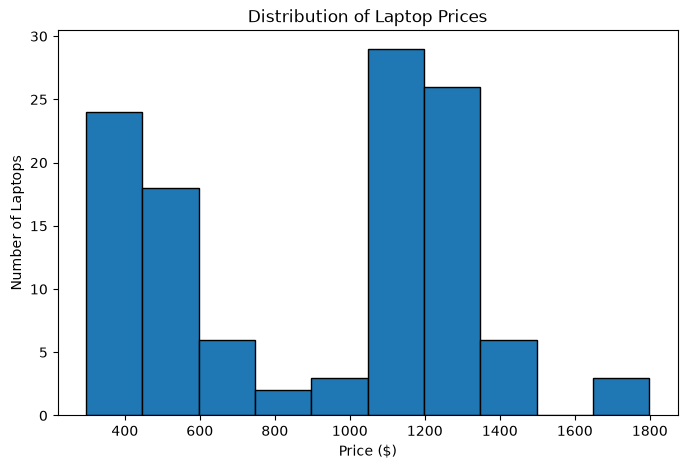

In [37]:
plt.figure(figsize=(8,5))
plt.hist(df["Price"], bins=10,edgecolor="Black")
plt.title("Distribution of Laptop Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Laptops")
plt.show()

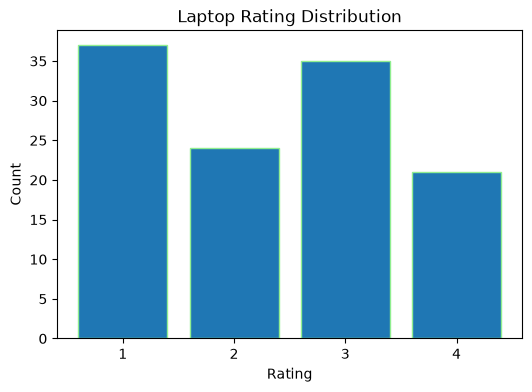

In [38]:
rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(rating_counts.index.astype(str), rating_counts.values,edgecolor="lightgreen")
plt.title("Laptop Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

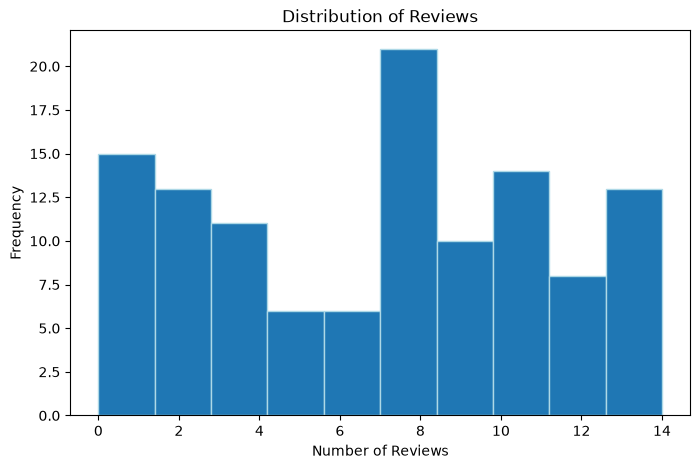

In [39]:
plt.figure(figsize=(8,5))
plt.hist(df["Reviews"], bins=10,edgecolor="lightblue")
plt.title("Distribution of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Frequency")
plt.show()

In [40]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[(df["Price"] < lower_limit) | (df["Price"] > upper_limit)]

print("Lower Limit :", lower_limit)
print("Upper Limit :", upper_limit)
print("Number of Outliers :", len(outliers))

outliers[["Laptop_Name", "Price"]]

Lower Limit : -659.6199999999998
Upper Limit : 2350.2999999999997
Number of Outliers : 0


,Laptop_Name,Price


C:\Users\ACER\AppData\Local\Temp\ipykernel_19240\28843488.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["Price"], vert=True)


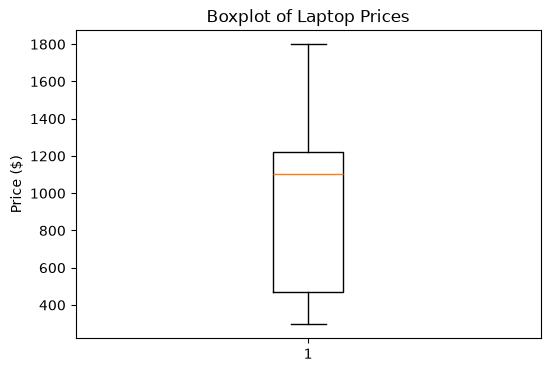

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(df["Price"], vert=True)

plt.title("Boxplot of Laptop Prices")
plt.ylabel("Price ($)")

plt.show()

In [42]:
corr = df[["Price","Rating","Reviews","RAM_GB","Storage_GB","Screen_Size"]].corr()

corr

,Price,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size
Price,1.000000,-0.095653,0.076006,0.248351,0.303079,0.335023
Rating,-0.095653,1.000000,0.168439,0.116420,-0.101066,0.008974
Reviews,0.076006,0.168439,1.000000,-0.115008,0.123423,0.000991
RAM_GB,0.248351,0.116420,-0.115008,1.000000,0.060722,0.087165
Storage_GB,0.303079,-0.101066,0.123423,0.060722,1.000000,-0.139117
Screen_Size,0.335023,0.008974,0.000991,0.087165,-0.139117,1.000000


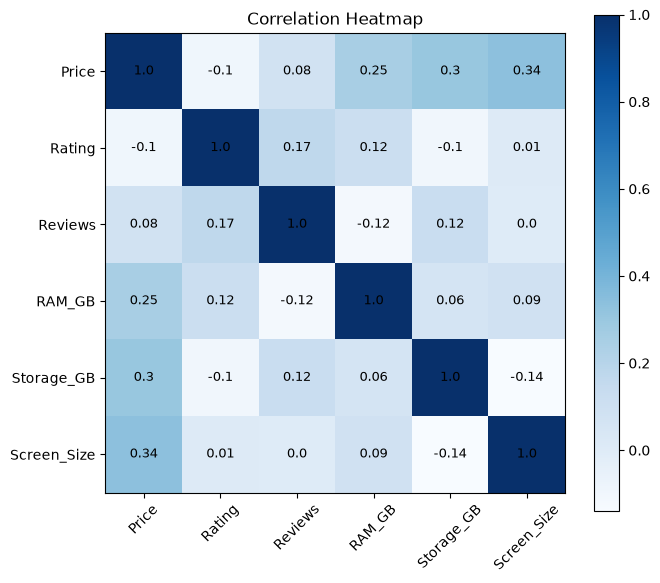

In [43]:
plt.figure(figsize=(7,6))

plt.imshow(corr, cmap="Blues")
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Heatmap")

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha="center", va="center", fontsize=9)

plt.tight_layout()
plt.show()

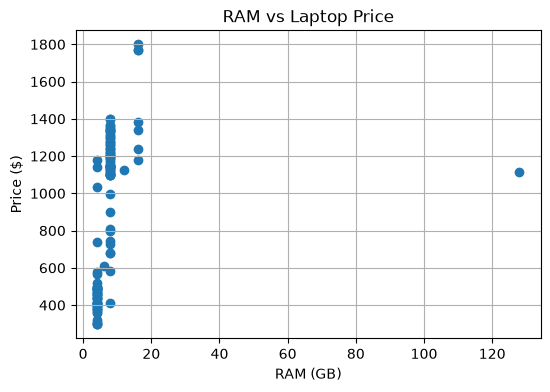

In [44]:

plt.figure(figsize=(6,4))
plt.scatter(df["RAM_GB"], df["Price"])
plt.title("RAM vs Laptop Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price ($)")
plt.grid(True)
plt.show()

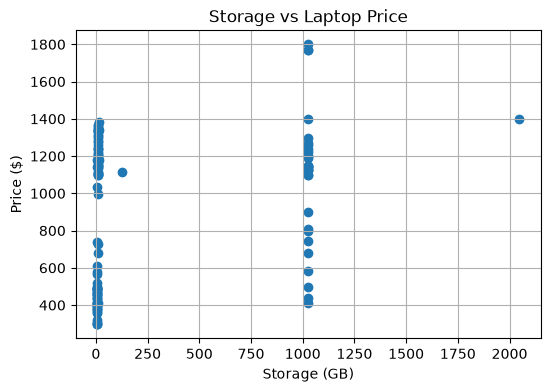

In [45]:
plt.figure(figsize=(6,4))
plt.scatter(df["Storage_GB"], df["Price"])
plt.title("Storage vs Laptop Price")
plt.xlabel("Storage (GB)")
plt.ylabel("Price ($)")
plt.grid(True)
plt.show()

Distribution   (Normal)

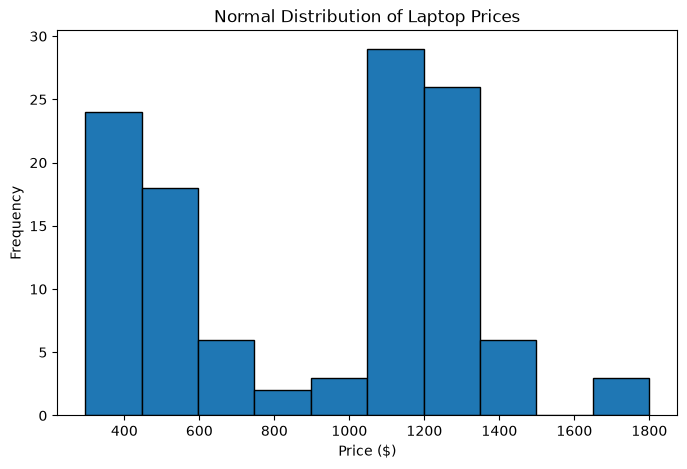

In [46]:
plt.figure(figsize=(8,5))
plt.hist(df["Price"], bins=10,edgecolor="black")

plt.title("Normal Distribution of Laptop Prices")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.show()

In [47]:
mean_price = df["Price"].mean()
std_price = df["Price"].std()

print("Mean Price :", round(mean_price,2))
print("Standard Deviation :", round(std_price,2))

Mean Price : 909.39
Standard Deviation : 401.31


In [48]:
population_size = len(df)

print("Population Size:", population_size)

Population Size: 117


In [49]:
population_mean = df["Price"].mean()

print("Population Mean Price:", round(population_mean,2))

Population Mean Price: 909.39


In [50]:
sample_df = df.sample(n=30, replace=False, random_state=42)

sample_df.head()

,Laptop_Name,Price,Description,Reviews,Rating,Screen_Size,RAM_GB,Storage_GB
44,Acer Aspire ES...,410.46,"Acer Aspire ES1-732 Black, 17.3"" HD+, Celeron,...",14,4,1.0,4.0,1024
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3,12.5,8.0,8
53,Lenovo V110-15...,465.95,"Lenovo V110-15IKB, 15.6"" HD, Core i5-7200U, 4G...",7,1,110.0,4.0,4
42,Acer Aspire 3...,408.98,"Acer Aspire 3 A315-31 Black, 15.6"" HD, Pentium...",10,4,3.0,4.0,4
10,ThinkPad X230,1244.99,"12.5"", Core i5 2.6GHz, 8GB, 180GB SSD, Win7 Pr...",10,3,12.5,8.0,8


In [51]:
sample_mean = sample_df["Price"].mean()

print("Sample Mean Price:", round(sample_mean,2))

Sample Mean Price: 920.44


In [52]:
comparison = pd.DataFrame({
    "Dataset": ["Population", "Sample"],
    "Mean Price": [
        round(df["Price"].mean(),2),
        round(sample_df["Price"].mean(),2)
    ],
    "Std Dev": [
        round(df["Price"].std(),2),
        round(sample_df["Price"].std(),2)
    ],
    "Size": [
        len(df),
        len(sample_df)
    ]
})

comparison

,Dataset,Mean Price,Std Dev,Size
0,Population,909.39,401.31,117
1,Sample,920.44,413.37,30


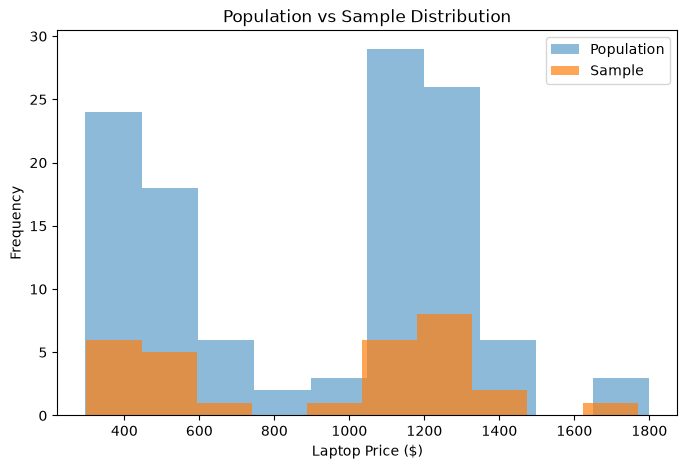

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(df["Price"], bins=10, alpha=0.5, label="Population")
plt.hist(sample_df["Price"], bins=10, alpha=0.7, label="Sample")

plt.title("Population vs Sample Distribution")
plt.xlabel("Laptop Price ($)")
plt.ylabel("Frequency")
plt.legend()

plt.show()

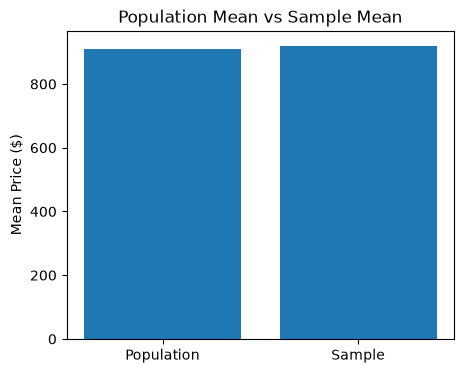

In [54]:
plt.figure(figsize=(5,4))

labels = ["Population", "Sample"]
means = [population_mean, sample_mean]

plt.bar(labels, means)

plt.title("Population Mean vs Sample Mean")
plt.ylabel("Mean Price ($)")

plt.show()

In [55]:
sample_with_replacement = df.sample(
    n=30,
    replace=True,
    random_state=42
)

sample_with_replacement.head()

,Laptop_Name,Price,Description,Reviews,Rating,Screen_Size,RAM_GB,Storage_GB
102,Hewlett Packar...,1273.11,Hewlett Packard Spectre 13-v106na Dark Ash Sil...,8,3,13.0,8.0,8
51,Lenovo V110-15...,454.73,"Lenovo V110-15ISK, 15.6"" HD, Core i3-6006U, 4G...",2,2,110.0,4.0,4
92,Lenovo Yoga 91...,1199.73,"Lenovo Yoga 910 Grey, 13.9"" FHD Touch, Core i5...",7,3,910.0,8.0,8
14,Asus VivoBook...,399.00,Asus VivoBook Max X541NA-GQ041 Black Chocolate...,4,1,541.0,4.0,4
106,Hewlett Packar...,1326.83,"Hewlett Packard ProBook 640 G3, 14"" FHD, Core ...",2,1,640.0,8.0,8


CLT


In [56]:
population = df["Price"]

print("Population Size:", len(population))
print("Population Mean:", round(population.mean(),2))

Population Size: 117
Population Mean: 909.39


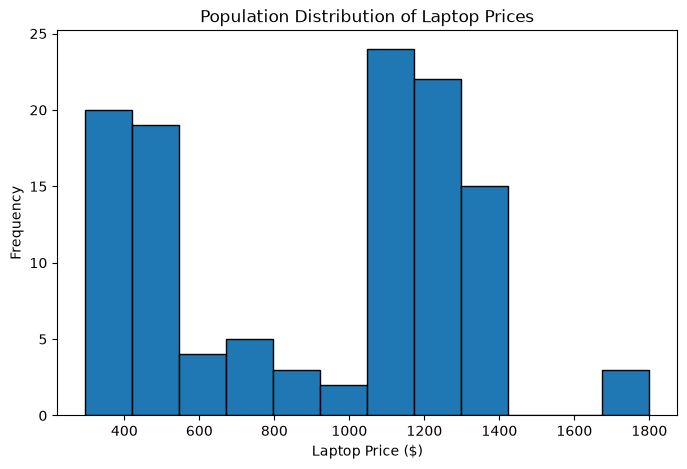

In [57]:
plt.figure(figsize=(8,5))

plt.hist(population, bins=12, edgecolor="black")

plt.title("Population Distribution of Laptop Prices")
plt.xlabel("Laptop Price ($)")
plt.ylabel("Frequency")

plt.show()

In [58]:
import numpy as np
sample_size = 30
num_samples = 500

sample_means = []

for i in range(num_samples):
    sample = population.sample(n=sample_size, replace=True)
    sample_means.append(sample.mean())

sample_means = np.array(sample_means)

print("Number of Repeated Samples:", num_samples)

Number of Repeated Samples: 500


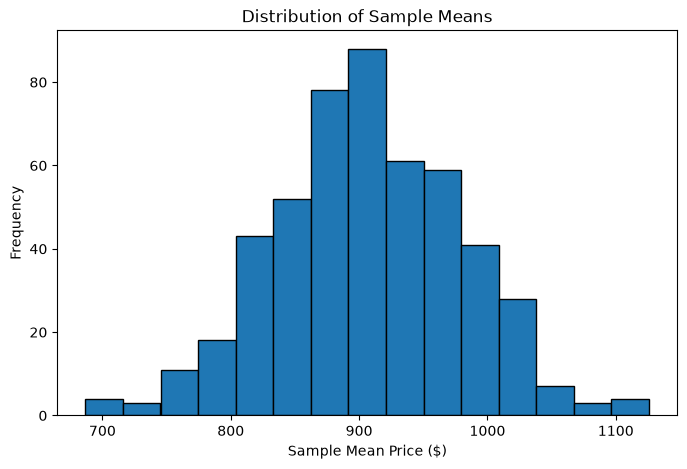

In [59]:
plt.figure(figsize=(8,5))

plt.hist(sample_means, bins=15, edgecolor="Black")

plt.title("Distribution of Sample Means")
plt.xlabel("Sample Mean Price ($)")
plt.ylabel("Frequency")

plt.show()

In [60]:
population_mean = population.mean()
estimated_mean = sample_means.mean()

print("Population Mean :", round(population_mean,2))
print("Estimated Mean  :", round(estimated_mean,2))

Population Mean : 909.39
Estimated Mean  : 906.85


In [61]:
comparison = pd.DataFrame({
    "Measure": ["Population Mean", "Estimated Mean"],
    "Price": [population_mean, estimated_mean]
})

comparison

,Measure,Price
0,Population Mean,909.393846
1,Estimated Mean,906.845691


In [62]:
sizes = [5, 30, 60]
results = {}

for size in sizes:

    means = []

    for i in range(500):
        sample = population.sample(n=size, replace=True)
        means.append(sample.mean())

    results[size] = means

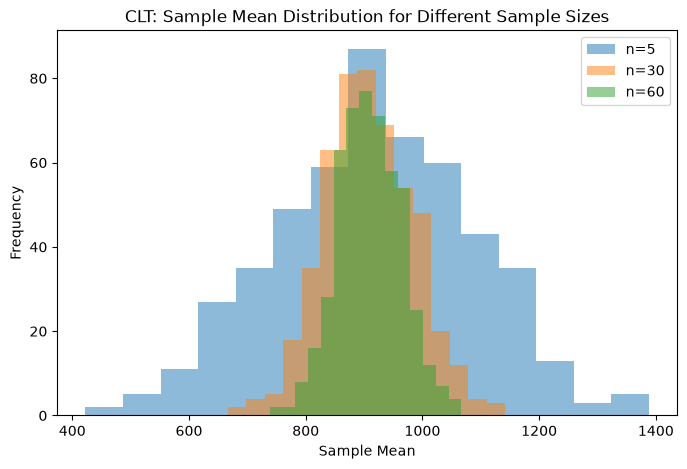

In [63]:
plt.figure(figsize=(8,5))

plt.hist(results[5], bins=15, alpha=0.5, label="n=5")
plt.hist(results[30], bins=15, alpha=0.5, label="n=30")
plt.hist(results[60], bins=15, alpha=0.5, label="n=60")

plt.title("CLT: Sample Mean Distribution for Different Sample Sizes")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.legend()

plt.show()

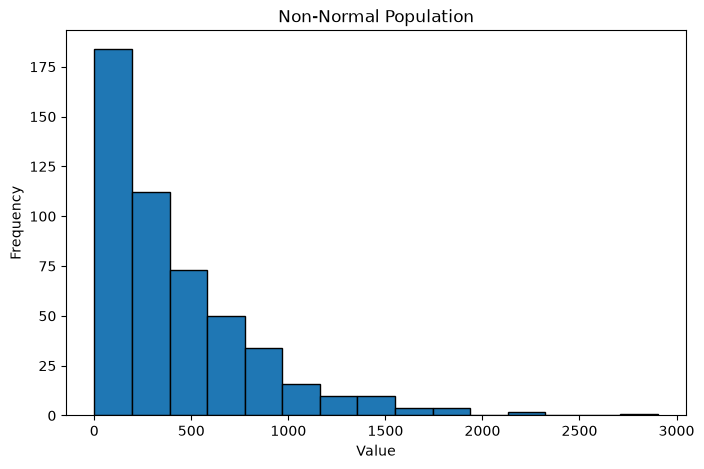

In [64]:
non_normal = np.random.exponential(scale=400, size=500)

plt.figure(figsize=(8,5))

plt.hist(non_normal, bins=15, edgecolor="Black")

plt.title("Non-Normal Population")
plt.xlabel("Value")
plt.ylabel("Frequency")

plt.show()

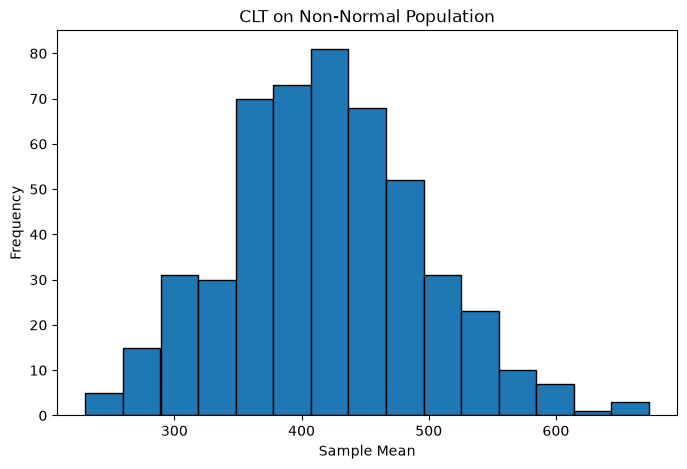

In [65]:
sample_means_non_normal = []

for i in range(500):

    sample = np.random.choice(non_normal, size=30, replace=True)

    sample_means_non_normal.append(sample.mean())

plt.figure(figsize=(8,5))

plt.hist(sample_means_non_normal, bins=15, edgecolor="Black")

plt.title("CLT on Non-Normal Population")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")

plt.show()

In [66]:
# Display the column names in our dataset
print("Dataset Columns:")
print(df.columns)

# Display the first five rows
print("\nFirst Five Rows:")
display(df.head())

Dataset Columns:
Index(['Laptop_Name', 'Price', 'Description', 'Reviews', 'Rating',
       'Screen_Size', 'RAM_GB', 'Storage_GB'],
      dtype='str')

First Five Rows:


,Laptop_Name,Price,Description,Reviews,Rating,Screen_Size,RAM_GB,Storage_GB
0,Packard 255 G2,416.99,"15.6"", AMD E2-3800 1.3GHz, 4GB, 500GB, Windows...",2,2,15.6,4.0,4
1,Aspire E1-510,306.99,"15.6"", Pentium N3520 2.16GHz, 4GB, 500GB, Linux",2,3,15.6,4.0,4
2,ThinkPad T540p,1178.99,"15.6"", Core i5-4200M, 4GB, 500GB, Win7 Pro 64bit",2,1,15.6,4.0,4
3,ProBook,739.99,"14"", Core i5 2.6GHz, 4GB, 500GB, Win7 Pro 64bit",8,4,14.0,4.0,4
4,ThinkPad X240,1311.99,"12.5"", Core i5-4300U, 8GB, 240GB SSD, Win7 Pro...",12,3,12.5,8.0,8


In [67]:
import numpy as np
from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


95% confidence interval for laptop prices

In [68]:
# Extract laptop prices
prices = df["Price"].dropna()

# Calculate sample mean
mean_price = prices.mean()

# Calculate standard error
standard_error = stats.sem(prices)

# Calculate 95% confidence interval
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(prices) - 1,
    loc=mean_price,
    scale=standard_error
)

print("Mean Laptop Price:", round(mean_price, 2))
print("95% Confidence Interval:", confidence_interval)

Mean Laptop Price: 909.39
95% Confidence Interval: (np.float64(835.9101363796179), np.float64(982.8775559280747))


One-Sample t-Test

In [69]:
# Set the reference price
reference_price = 500

# Perform a one-sample t-test
t_statistic, p_value = stats.ttest_1samp(
    prices,
    reference_price
)

print("Reference Price:", reference_price)
print("T-Statistic:", round(t_statistic, 4))
print("P-Value:", round(p_value, 4))

# Interpret the result
if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("The average laptop price is significantly different from the reference price.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence that the average laptop price differs from the reference price.")

Reference Price: 500
T-Statistic: 11.0345
P-Value: 0.0
Reject the null hypothesis.
The average laptop price is significantly different from the reference price.


Perform a Z-Test

In [70]:
# Set the reference mean and assumed population standard deviation
reference_mean = 500
population_std = 100

# Calculate the sample mean and size
sample_mean = prices.mean()
sample_size = len(prices)

# Calculate the Z-statistic
z_statistic = (
    sample_mean - reference_mean
) / (
    population_std / np.sqrt(sample_size)
)

# Calculate the two-tailed p-value
p_value = 2 * stats.norm.sf(abs(z_statistic))

print("Sample Mean:", round(sample_mean, 2))
print("Reference Mean:", reference_mean)
print("Z-Statistic:", round(z_statistic, 4))
print("P-Value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Sample Mean: 909.39
Reference Mean: 500
Z-Statistic: 44.2827
P-Value: 0.0
Reject the null hypothesis.


In [71]:
numeric_columns = [
    "Price",
    "Rating",
    "Reviews",
    "RAM_GB",
    "Storage_GB",
    "Screen_Size"
]

# Keep columns that exist in the dataset
numeric_columns = [
    col for col in numeric_columns if col in df.columns
]

# Convert selected columns to numeric
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Calculate covariance
covariance_matrix = df[numeric_columns].cov()

print("Covariance Matrix:")
display(covariance_matrix.round(2))

Covariance Matrix:


,Price,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size
Price,161050.86,-42.52,129.80,1154.75,58218.33,250902.68
Rating,-42.52,1.23,0.79,1.49,-53.58,18.55
Reviews,129.80,0.79,18.11,-5.67,251.41,7.87
RAM_GB,1154.75,1.49,-5.67,134.24,336.75,1884.66
Storage_GB,58218.33,-53.58,251.41,336.75,229111.11,-124265.88
Screen_Size,250902.68,18.55,7.87,1884.66,-124265.88,3482554.38


covariance matrix


In [72]:
# Correlation Matrix

correlation_matrix = df[numeric_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Price,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size
Price,1.00,-0.10,0.08,0.25,0.30,0.34
Rating,-0.10,1.00,0.17,0.12,-0.10,0.01
Reviews,0.08,0.17,1.00,-0.12,0.12,0.00
RAM_GB,0.25,0.12,-0.12,1.00,0.06,0.09
Storage_GB,0.30,-0.10,0.12,0.06,1.00,-0.14
Screen_Size,0.34,0.01,0.00,0.09,-0.14,1.00


Correlation Matrix

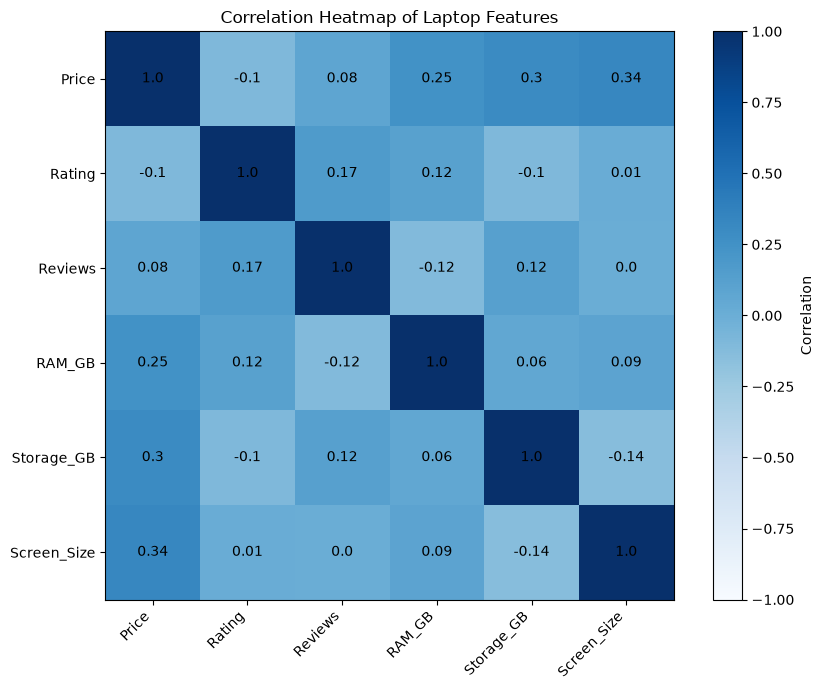

In [73]:
# Correlation Heatmap

plt.figure(figsize=(9, 7))

plt.imshow(correlation_matrix, cmap="Blues", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap of Laptop Features")

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

One way ANOVA Test

In [74]:
from scipy import stats

# Prepare the data
anova_df = df[["Price", "Rating"]].dropna().copy()

# Create rating groups
anova_df["Rating_Group"] = pd.cut(
    anova_df["Rating"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Low Rating", "Medium Rating", "High Rating"]
)

# Calculate the prices for each group
low_prices = anova_df.loc[
    anova_df["Rating_Group"] == "Low Rating", "Price"
]

medium_prices = anova_df.loc[
    anova_df["Rating_Group"] == "Medium Rating", "Price"
]

high_prices = anova_df.loc[
    anova_df["Rating_Group"] == "High Rating", "Price"
]

print("Low Rating Records:", len(low_prices))
print("Medium Rating Records:", len(medium_prices))
print("High Rating Records:", len(high_prices))

# Perform ANOVA
if min(len(low_prices), len(medium_prices), len(high_prices)) > 0:

    f_statistic, p_value = stats.f_oneway(
        low_prices,
        medium_prices,
        high_prices
    )

    print("\nF-Statistic:", round(f_statistic, 4))
    print("P-Value:", round(p_value, 4))

    if p_value < 0.05:
        print("Reject the null hypothesis.")
        print("At least one group has a significantly different mean price.")
    else:
        print("Fail to reject the null hypothesis.")
        print("No significant difference in mean prices was detected.")

else:
    print("ANOVA cannot be performed because one or more groups are empty.")

Low Rating Records: 61
Medium Rating Records: 56
High Rating Records: 0
ANOVA cannot be performed because one or more groups are empty.


Chi-Square test


In [75]:
from scipy.stats import chi2_contingency

# Prepare the data
chi_df = df[["Price", "Rating"]].dropna().copy()

# Create three price categories
chi_df["Price_Category"] = pd.qcut(
    chi_df["Price"].rank(method="first"),
    q=3,
    labels=["Budget", "Mid-Range", "Premium"]
)

# Create rating categories
chi_df["Rating_Category"] = pd.cut(
    chi_df["Rating"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=["Low", "Medium", "High"]
)

# Create a contingency table
contingency_table = pd.crosstab(
    chi_df["Price_Category"],
    chi_df["Rating_Category"]
)

print("Contingency Table:")
display(contingency_table)

# Perform the Chi-Square test
chi_statistic, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("Chi-Square Statistic:", round(chi_statistic, 4))
print("Degrees of Freedom:", degrees_of_freedom)
print("P-Value:", round(p_value, 4))

if p_value < 0.05:
    print("Reject the null hypothesis.")
    print("Price category and rating category are associated.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association.")

# Check expected frequencies
print(
    "\nExpected frequencies below 5:",
    int((expected < 5).sum())
)

Contingency Table:


Rating_Category,Low,Medium
Price_Category,,
Budget,17,22
Mid-Range,24,15
Premium,20,19


Chi-Square Statistic: 2.5345
Degrees of Freedom: 2
P-Value: 0.2816
Fail to reject the null hypothesis.
There is insufficient evidence of an association.

Expected frequencies below 5: 0


In [76]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Regression libraries imported successfully!")

Regression libraries imported successfully!


In [77]:
# Define the input features
features = [
    "Rating",
    "Reviews",
    "RAM_GB",
    "Storage_GB",
    "Screen_Size"
]

# Keep only features available in the dataset
features = [
    col for col in features
    if col in df.columns
]

# Create a separate regression dataset
regression_df = df[features + ["Price"]].copy()

# Convert columns to numeric
for col in features + ["Price"]:
    regression_df[col] = pd.to_numeric(
        regression_df[col],
        errors="coerce"
    )

# Replace infinite values with missing values
regression_df = regression_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove rows without a target price
regression_df = regression_df.dropna(subset=["Price"])

# Fill missing feature values with their medians
for col in features:
    regression_df[col] = regression_df[col].fillna(
        regression_df[col].median()
    )

# Remove features that contain no usable values
features = [
    col for col in features
    if regression_df[col].notna().any()
]

# Separate features and target
X = regression_df[features]
y = regression_df["Price"]

print("Input Features:", features)
print("Total Records:", len(regression_df))

display(regression_df.head())

Input Features: ['Rating', 'Reviews', 'RAM_GB', 'Storage_GB', 'Screen_Size']
Total Records: 117


,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size,Price
0,2,2,4.0,4,15.6,416.99
1,3,2,4.0,4,15.6,306.99
2,1,2,4.0,4,15.6,1178.99
3,4,8,4.0,4,14.0,739.99
4,3,12,8.0,8,12.5,1311.99


In [78]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 93
Testing Records: 24


In [79]:
# Define regression models

regression_models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Decision Tree Regression": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest Regression": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Store the results
regression_results = []

# Train and evaluate each model
for name, model in regression_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    regression_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display the comparison
regression_results_df = pd.DataFrame(regression_results)

print("Regression Model Comparison:")
display(regression_results_df.round(4))

Regression Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,352.6641,156856.9798,396.0517,0.0714
1,Ridge Regression,351.6207,155647.3377,394.5217,0.0786
2,Lasso Regression,352.5687,156741.9223,395.9065,0.0721
3,Decision Tree Regression,228.1633,112138.5196,334.8709,0.3361
4,Random Forest Regression,152.8570,35503.3142,188.4232,0.7898


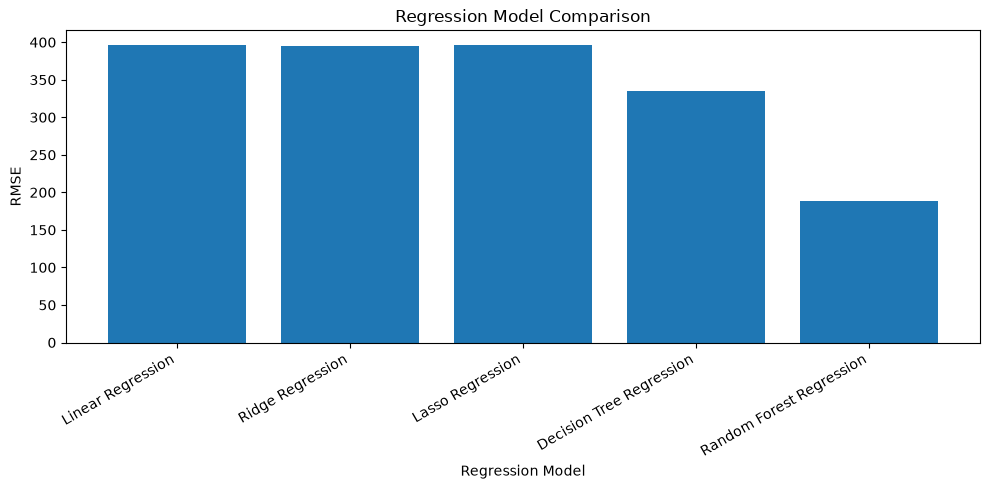

In [80]:
# Compare model performance using RMSE

plt.figure(figsize=(10, 5))

plt.bar(
    regression_results_df["Model"],
    regression_results_df["RMSE"]
)

plt.title("Regression Model Comparison")
plt.xlabel("Regression Model")
plt.ylabel("RMSE")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [81]:
# Select one laptop from the test dataset

sample_laptop = X_test.iloc[[0]]

# Get its actual price
actual_price = y_test.iloc[0]

# Use the trained Random Forest model
random_forest_model = regression_models[
    "Random Forest Regression"
]

# Predict the laptop price
predicted_price = random_forest_model.predict(
    sample_laptop
)[0]

print("Laptop Features:")
display(sample_laptop)

print("Actual Laptop Price:", round(actual_price, 2))
print("Predicted Laptop Price:", round(predicted_price, 2))

Laptop Features:


,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size
44,4,14,4.0,1024,1.0


Actual Laptop Price: 410.46
Predicted Laptop Price: 619.18


Actual vs Predicted Laptop Prices:


,Actual Price,Predicted Price
0,410.46,619.1816
1,1311.99,1175.8480
2,465.95,570.9097
3,408.98,418.1875
4,1244.99,1225.3493
5,1170.10,1293.4912
6,1123.87,933.9511
7,1212.16,896.8539
8,379.94,478.1579
9,520.99,720.4581


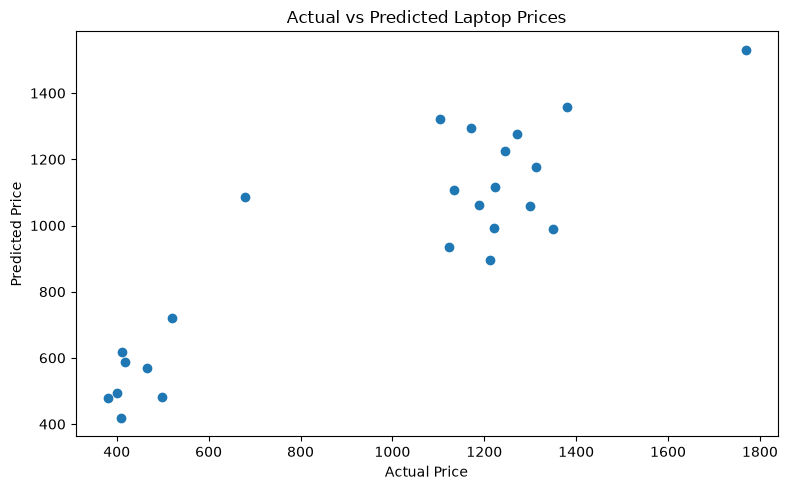

In [82]:
# Predict prices for all test records

predicted_prices = random_forest_model.predict(X_test)

# Create a comparison table
price_comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predicted_prices
})

print("Actual vs Predicted Laptop Prices:")
display(price_comparison.head(10))

# Plot actual and predicted prices
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    predicted_prices
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Laptop Prices")

plt.tight_layout()
plt.show()

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Classification libraries imported successfully!")

Classification libraries imported successfully!


Create Peice Categories

In [86]:
# Copy the dataset
classification_df = df.copy()

# Convert price to numeric
classification_df["Price"] = pd.to_numeric(
    classification_df["Price"],
    errors="coerce"
)

# Remove records without valid prices
classification_df = classification_df.dropna(
    subset=["Price"]
)

# Create three price categories
classification_df["Price_Category"] = pd.qcut(
    classification_df["Price"].rank(method="first"),
    q=3,
    labels=["Budget", "Mid-Range", "Premium"]
)

print("Price Category Counts:")
display(
    classification_df["Price_Category"].value_counts()
)

print("Dataset with Price Categories:")
display(
    classification_df[
        ["Laptop_Name", "Price", "Price_Category"]
    ].head()
)

Price Category Counts:


Price_Category
Budget       39
Mid-Range    39
Premium      39
Name: count, dtype: int64

Dataset with Price Categories:


,Laptop_Name,Price,Price_Category
0,Packard 255 G2,416.99,Budget
1,Aspire E1-510,306.99,Budget
2,ThinkPad T540p,1178.99,Premium
3,ProBook,739.99,Mid-Range
4,ThinkPad X240,1311.99,Premium


In [87]:
# Select input features
features = [
    "Rating",
    "Reviews",
    "RAM_GB",
    "Storage_GB",
    "Screen_Size"
]

# Keep available columns
features = [
    col for col in features
    if col in classification_df.columns
]

# Prepare the dataset
classification_data = classification_df[
    features + ["Price_Category"]
].copy()

# Convert input features to numeric
for col in features:
    classification_data[col] = pd.to_numeric(
        classification_data[col],
        errors="coerce"
    )

# Replace infinite values
classification_data = classification_data.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove rows with missing target categories
classification_data = classification_data.dropna(
    subset=["Price_Category"]
)

# Fill missing feature values with their medians
for col in features:
    classification_data[col] = classification_data[col].fillna(
        classification_data[col].median()
    )

# Remove features that contain only missing values
features = [
    col for col in features
    if classification_data[col].notna().any()
]

# Separate features and target
X = classification_data[features]
y = classification_data["Price_Category"]

print("Input Features:", features)
print("Total Records:", len(classification_data))

display(classification_data.head())

Input Features: ['Rating', 'Reviews', 'RAM_GB', 'Storage_GB', 'Screen_Size']
Total Records: 117


,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size,Price_Category
0,2,2,4.0,4,15.6,Budget
1,3,2,4.0,4,15.6,Budget
2,1,2,4.0,4,15.6,Premium
3,4,8,4.0,4,14.0,Mid-Range
4,3,12,8.0,8,12.5,Premium


In [88]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 93
Testing Records: 24


In [89]:
# Define classification models

classification_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Store evaluation results
classification_results = []

# Train and evaluate each model
for name, model in classification_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# Display results
classification_results_df = pd.DataFrame(
    classification_results
)

print("Classification Model Comparison:")
display(classification_results_df.round(4))

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.5000,0.4694,0.5000,0.4795
1,Decision Tree,0.5833,0.5593,0.5833,0.5623
2,Random Forest,0.6667,0.6278,0.6667,0.5963


In [90]:
# Select the Random Forest classifier
best_classifier = classification_models["Random Forest"]

# Generate predictions
predictions = best_classifier.predict(X_test)

# Display the classification report
print("Classification Report:")

print(
    classification_report(
        y_test,
        predictions,
        labels=["Budget", "Mid-Range", "Premium"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

      Budget       0.80      1.00      0.89         8
   Mid-Range       0.50      0.12      0.20         8
     Premium       0.58      0.88      0.70         8

    accuracy                           0.67        24
   macro avg       0.63      0.67      0.60        24
weighted avg       0.63      0.67      0.60        24



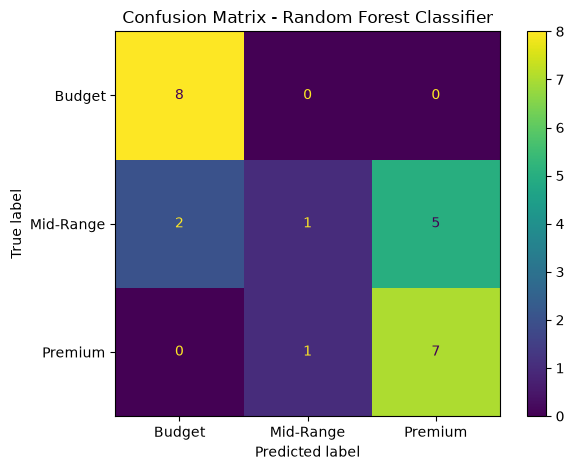

In [91]:
# Calculate the confusion matrix

cm = confusion_matrix(
    y_test,
    predictions,
    labels=["Budget", "Mid-Range", "Premium"]
)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Budget", "Mid-Range", "Premium"]
)

display.plot()

plt.title("Confusion Matrix - Random Forest Classifier")
plt.tight_layout()
plt.show()

In [92]:
from IPython.display import display

# Select one laptop from the test dataset
sample_laptop = X_test.iloc[[0]]

# Predict its price category
predicted_category = best_classifier.predict(
    sample_laptop
)[0]

print("Laptop Features:")
display(sample_laptop)

print("Predicted Price Category:", predicted_category)

Laptop Features:


,Rating,Reviews,RAM_GB,Storage_GB,Screen_Size
16,2,0,4.0,4,5.0


Predicted Price Category: Budget


In [ ]:
%pip install streamlit pandas numpy scikit-learn

In [ ]:

%%writefile laptop_app.py

import streamlit as st
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score

st.set_page_config(
    page_title="Laptop Price Prediction",
    page_icon="💻",
    layout="wide"
)

st.title("💻 Used Laptop Resale Value Prediction")
st.write(
    "Estimate a laptop's price and classify it as Budget, "
    "Mid-Range, or Premium using Machine Learning."
)

st.sidebar.header("Dataset")
uploaded_file = st.sidebar.file_uploader(
    "Upload cleaned_used_laptops.csv",
    type=["csv"]
)

@st.cache_data
def load_data(file_bytes):
    import io
    return pd.read_csv(io.BytesIO(file_bytes))

try:
    if uploaded_file is not None:
        df = load_data(uploaded_file.getvalue())
    else:
        df = pd.read_csv("cleaned_used_laptops.csv")

    required_columns = [
        "Price", "Rating", "Reviews",
        "RAM_GB", "Storage_GB", "Screen_Size"
    ]

    missing = [c for c in required_columns if c not in df.columns]

    if missing:
        st.error("Missing required columns: " + ", ".join(missing))
        st.stop()

    features = [
        "Rating", "Reviews", "RAM_GB",
        "Storage_GB", "Screen_Size"
    ]

    for col in required_columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=["Price"])

    if len(df) < 10:
        st.error("The dataset must contain at least 10 valid price records.")
        st.stop()

    # Prepare features and target
    X = df[features]
    y = df["Price"]

    # Split the dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train regression model
    regression_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100, random_state=42
        ))
    ])

    regression_model.fit(X_train, y_train)
    predictions = regression_model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    # Create price categories from the dataset
    df["Price_Category"] = pd.qcut(
        df["Price"].rank(method="first"),
        q=3,
        labels=["Budget", "Mid-Range", "Premium"]
    )

    Xc = df[features]
    yc = df["Price_Category"]

    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        Xc, yc,
        test_size=0.2,
        random_state=42,
        stratify=yc
    )

    # Train classification model
    classification_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100, random_state=42
        ))
    ])

    classification_model.fit(X_train_c, y_train_c)
    class_predictions = classification_model.predict(X_test_c)

    accuracy = accuracy_score(y_test_c, class_predictions)

    # Dashboard metrics
    st.subheader("📊 Dataset Overview")

    c1, c2, c3 = st.columns(3)
    c1.metric("Laptop Records", len(df))
    c2.metric("Mean Price", f"${df['Price'].mean():,.2f}")
    c3.metric("Features Used", len(features))

    st.subheader("🔍 Explore the Dataset")
    st.dataframe(df.head(10), use_container_width=True)

    with st.expander("View model evaluation"):
        m1, m2, m3 = st.columns(3)
        m1.metric("Mean Absolute Error", f"${mae:,.2f}")
        m2.metric("R² Score", f"{r2:.3f}")
        m3.metric("Classification Accuracy", f"{accuracy:.1%}")

        st.caption(
            "These metrics are calculated on a held-out test set. "
            "They measure performance on this dataset, not guaranteed "
            "real-world resale accuracy."
        )

    # Prediction interface
    st.subheader("🧮 Predict Laptop Resale Value")
    st.write("Enter the laptop specifications below.")

    median = X.median(numeric_only=True)

    col1, col2 = st.columns(2)

    with col1:
        rating = st.number_input(
            "Rating (0–5)", min_value=0.0, max_value=5.0,
            value=float(np.clip(median["Rating"], 0, 5)),
            step=0.1
        )

        reviews = st.number_input(
            "Number of Reviews", min_value=0,
            value=max(0, int(median["Reviews"])),
            step=1
        )

        ram = st.number_input(
            "RAM (GB)", min_value=1, max_value=1024,
            value=max(1, int(median["RAM_GB"])),
            step=1
        )

    with col2:
        storage = st.number_input(
            "Storage (GB)", min_value=1, max_value=100000,
            value=max(1, int(median["Storage_GB"])),
            step=1
        )

        screen_size = st.number_input(
            "Screen Size (inches)", min_value=1.0, max_value=100.0,
            value=float(np.clip(median["Screen_Size"], 1, 100)),
            step=0.1
        )

    if st.button("Predict Laptop Value", type="primary"):
        input_data = pd.DataFrame([{
            "Rating": rating,
            "Reviews": reviews,
            "RAM_GB": ram,
            "Storage_GB": storage,
            "Screen_Size": screen_size
        }])

        predicted_price = regression_model.predict(input_data)[0]
        predicted_category = classification_model.predict(input_data)[0]

        probabilities = classification_model.predict_proba(input_data)[0]
        classes = classification_model.named_steps["model"].classes_
        confidence = max(probabilities) * 100

        st.success(f"Estimated Laptop Price: ${predicted_price:,.2f}")
        st.info(f"Predicted Price Category: {predicted_category}")
        st.write(f"Classification Model Confidence: {confidence:.2f}%")

        st.caption(
            "This is an estimate from the trained model, not a guaranteed "
            "resale price. The dataset may not represent current market prices."
        )

except FileNotFoundError:
    st.warning(
        "Dataset not found. Place cleaned_used_laptops.csv in the "
        "same folder as laptop_app.py, or upload it using the sidebar."
    )

except Exception as e:
    st.error(f"Unable to load or process the dataset: {e}")
